# Demo interactivo: nivelación de terreno con DQN

1. **Elegí una seed** y obtené el terreno que genera (`GET /terreno/{seed}`). Lo podés ver en **2D** (mapa de calor) o en **3D** (relieve actual y objetivo lado a lado, que se rotan juntos con los sliders *Elevación* y *Giro*).
2. **Enviá el terreno a resolver** (`POST /resolver`): la API lo resuelve con el agente DQN y con el greedy de origen más cercano.
3. Explorá el resultado: **Comparación** de recorridos, **animación paso a paso** y **tabla** de viajes.

**Requisitos:** la API levantada (`docker run -p 8000:8000 nivelacion-api` o `uvicorn api.main:app`) y las librerías del notebook: `pip install -r requirements-notebook.txt`. Si la API no está en `localhost:8000`, definí la variable de entorno `API_URL`.

Colores: *rojo* = hay que excavar (altura actual > objetivo), *azul* = hay que rellenar.

In [ ]:
import json
import os
import urllib.error
import urllib.request

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import clear_output, display
from matplotlib.colors import TwoSlopeNorm

%matplotlib inline

API_URL = os.environ.get("API_URL", "http://localhost:8000")


def pedir(metodo, ruta, cuerpo=None):
    """Llama a la API y devuelve el JSON de la respuesta (usa solo la librería estándar)."""
    datos = None if cuerpo is None else json.dumps(cuerpo).encode()
    pedido = urllib.request.Request(
        API_URL + ruta, data=datos, method=metodo, headers={"Content-Type": "application/json"}
    )
    try:
        with urllib.request.urlopen(pedido, timeout=30) as respuesta:
            return json.load(respuesta)
    except urllib.error.HTTPError as error:
        raise RuntimeError(f"La API respondió {error.code}: {error.read().decode()}") from error
    except urllib.error.URLError as error:
        raise RuntimeError(f"No se pudo conectar con la API en {API_URL}.") from error


print("API:", pedir("GET", "/health"))
modelo = pedir("GET", "/modelo")
print("Modelo:", modelo["ruta"], "| arquitectura:", modelo["config"].get("arquitectura"), "| gamma:", modelo["config"].get("gamma"))

API: {'estado': 'ok'}
Modelo: /app/modelo/modelo_final.pt | arquitectura: por_viaje | gamma: 0.39


## Funciones de dibujo

In [ ]:
def diferencia_en_paso(diferencia, orden, k):
    """Terreno (actual − objetivo) después de hacer los primeros k viajes, excavar baja el origen y rellenar sube el destino."""
    d = diferencia.copy()
    for viaje in orden[:k]:
        d[tuple(viaje["origen"])] -= viaje["volumen"]
        d[tuple(viaje["destino"])] += viaje["volumen"]
    return d


def norma(diferencia):
    limite = max(abs(diferencia).max(), 1)
    return TwoSlopeNorm(0, -limite, limite)


def numerar(eje, matriz):
    for (i, j), v in np.ndenumerate(matriz):
        eje.text(j, i, v, ha="center", va="center", fontsize=8)


def dibujar_terreno_2d(seed, alturas, objetivo):
    diferencia = alturas - objetivo
    fig, ejes = plt.subplots(1, 3, figsize=(14, 4.2))
    vmin, vmax = min(alturas.min(), objetivo.min()), max(alturas.max(), objetivo.max())
    for eje, matriz, titulo in [(ejes[0], alturas, "Alturas actuales"), (ejes[1], objetivo, "Alturas objetivo")]:
        imagen = eje.imshow(matriz, cmap="terrain", vmin=vmin, vmax=vmax)
        eje.set_title(titulo)
        fig.colorbar(imagen, ax=eje, shrink=0.8)
        numerar(eje, matriz)
    imagen = ejes[2].imshow(diferencia, cmap="RdBu_r", norm=norma(diferencia))
    ejes[2].set_title("Actual − objetivo (rojo: excavar, azul: rellenar)")
    fig.colorbar(imagen, ax=ejes[2], shrink=0.8)
    numerar(ejes[2], diferencia)
    for eje in ejes:
        eje.set_xticks(range(alturas.shape[1]))
        eje.set_yticks(range(alturas.shape[0]))
    fig.suptitle(f"Terreno de la seed {seed}")
    plt.tight_layout()
    plt.show()


def dibujar_terreno_3d(seed, alturas, objetivo, elev=35, azim=-60):
    """Relieve actual y objetivo en 3D, lado a lado y con la misma escala de altura."""
    filas, columnas = np.indices(alturas.shape)
    vmin, vmax = min(alturas.min(), objetivo.min()), max(alturas.max(), objetivo.max())
    fig = plt.figure(figsize=(14, 6))
    for posicion, (matriz, titulo) in enumerate([(alturas, "Terreno actual"), (objetivo, "Terreno objetivo")], start=1):
        eje = fig.add_subplot(1, 2, posicion, projection="3d")
        eje.plot_surface(columnas, filas, matriz, cmap="terrain", vmin=vmin, vmax=vmax, edgecolor="k", linewidth=0.3)
        eje.set_zlim(vmin - 0.5, vmax + 0.5)
        eje.set_xlabel("columna"); eje.set_ylabel("fila"); eje.set_zlabel("altura")
        eje.invert_yaxis()
        eje.view_init(elev=elev, azim=azim)
        eje.set_title(titulo)
    fig.suptitle(f"Seed {seed}")
    plt.tight_layout()
    plt.show()


def costo_acumulado(recorrido):
    return np.cumsum([p["distancia"] for p in recorrido["orden"]])


def distancia_cargada(recorrido):
    return sum(abs(p["origen"][0] - p["destino"][0]) + abs(p["origen"][1] - p["destino"][1]) for p in recorrido["orden"])


def dibujar_costos(eje, greedy, agente):
    """Costo total separado en tramo con carga y traslado en vacío."""
    cargado = distancia_cargada(greedy)
    vacios = [greedy["costo"] - cargado, agente["costo"] - cargado]
    eje.bar(["Greedy", "Agente DQN"], [cargado, cargado], color="#cccccc", label="Con carga (igual)")
    eje.bar(["Greedy", "Agente DQN"], vacios, bottom=[cargado, cargado], color=["#7570b3", "#1b9e77"], label="En vacío")
    for i, v in enumerate(vacios):
        eje.text(i, cargado + v / 2, f"vacío {v:.0f}", ha="center", va="center", color="white", fontsize=10)
        eje.text(i, cargado + v + 4, f"total {cargado + v:.0f}", ha="center", fontsize=10)
    eje.set_ylim(0, (cargado + max(vacios)) * 1.12)
    eje.set_ylabel("costo")
    eje.set_title("De dónde sale la diferencia")
    eje.legend(loc="lower right")


def dibujar_paso(eje, diferencia, orden, k, titulo, costo):
    """Estado después de k viajes: Todos los anteriores en gris, el actual en naranja y la máquina."""
    estado_k = diferencia_en_paso(diferencia, orden, k)
    eje.imshow(estado_k, cmap="RdBu_r", norm=norma(diferencia), alpha=0.4)
    numerar(eje, estado_k)
    posicion = (0, 0)
    for n, paso in enumerate(orden[:k], start=1):
        (fo, co), (fd, cd) = paso["origen"], paso["destino"]
        actual = n == k
        if actual:
            eje.plot([posicion[1], co], [posicion[0], fo], ls=":", color="black", lw=1.6)
        eje.annotate("", xy=(cd, fd), xytext=(co, fo),
                     arrowprops=dict(arrowstyle="-|>", color="#d95f02" if actual else "#aaa", alpha=1 if actual else 0.7,
                                     lw=3 if actual else 1, connectionstyle="arc3,rad=0.12", shrinkA=4, shrinkB=4),
                     zorder=4 if actual else 2)
        posicion = (fd, cd)
    eje.plot(0, 0, "ks", ms=8)
    eje.plot(posicion[1], posicion[0], "o", color="orange", mec="black", ms=12, zorder=5)
    eje.set_title(f"{titulo} — viaje {k}/{len(orden)}\ncosto acumulado {costo:.0f}")
    eje.set_xticks(range(diferencia.shape[1]))
    eje.set_yticks(range(diferencia.shape[0]))


def dibujar_curva(eje, greedy, agente, k=None):
    """Costo acumulado viaje a viaje: Dónde gana o pierde el agente respecto del greedy."""
    x = np.arange(1, len(greedy["orden"]) + 1)
    cg, ca = costo_acumulado(greedy), costo_acumulado(agente)
    eje.plot(x, cg, color="#7570b3", lw=2, label="Greedy")
    eje.plot(x, ca, color="#1b9e77", lw=2, label="Agente DQN")
    if k:
        eje.axvline(k, color="gray", ls="--", lw=1)
        eje.plot([k, k], [cg[k - 1], ca[k - 1]], "o", color="orange", mec="black")
    eje.set_xlabel("viaje")
    eje.set_ylabel("costo acumulado")
    eje.set_title("Costo acumulado")
    eje.grid(alpha=0.3)
    eje.legend()


## 1. Elegir una seed y ver el terreno

Las seeds 0–99 son las de test (el agente nunca las vio al entrenar). Probá con cualquiera entre 0 y 999999.

In [3]:
estado = {"info": None, "resultado": None}

seed_w = widgets.BoundedIntText(value=7, min=0, max=999_999, description="Seed:", layout=widgets.Layout(width="180px"))
vista_w = widgets.ToggleButtons(options=[("2D", "2d"), ("3D", "3d")], value="2d", description="Vista:")
elev_w = widgets.IntSlider(value=35, min=0, max=90, description="Elevación:", layout=widgets.Layout(width="260px"))
azim_w = widgets.IntSlider(value=-60, min=-180, max=180, description="Giro:", layout=widgets.Layout(width="260px"))
obtener_w = widgets.Button(description="Obtener terreno", button_style="info", icon="map")
resolver_w = widgets.Button(description="Enviar a resolver", button_style="success", icon="play", disabled=True)
mensaje_w = widgets.HTML()
salida_terreno = widgets.Output()


def mostrar_terreno(*_):
    info = estado["info"]
    if info is None:
        return
    alturas = np.array(info["terreno"]["alturas"])
    objetivo = np.array(info["terreno"]["objetivo"])
    with salida_terreno:
        clear_output(wait=True)
        if vista_w.value == "2d":
            dibujar_terreno_2d(info["seed"], alturas, objetivo)
        else:
            dibujar_terreno_3d(info["seed"], alturas, objetivo, elev_w.value, azim_w.value)


def al_obtener(_):
    estado["resultado"] = None
    try:
        info = pedir("GET", f"/terreno/{seed_w.value}")
    except RuntimeError as error:
        mensaje_w.value = f"<span style='color:#b00'>{error}</span>"
        return
    estado["info"] = info
    if info["resoluble"]:
        mensaje_w.value = f"Seed <b>{info['seed']}</b>: terreno de {info['terreno']['tamano']}×{info['terreno']['tamano']}, <b>{info['n_viajes']}</b> viajes."
    else:
        mensaje_w.value = (f"Seed <b>{info['seed']}</b>: este terreno necesita más viajes de los que soporta el modelo. "
                           "Probá con otra seed.")
    resolver_w.disabled = not info["resoluble"]
    mostrar_terreno()


obtener_w.on_click(al_obtener)
vista_w.observe(mostrar_terreno, names="value")
for control in (elev_w, azim_w):
    control.observe(lambda _: mostrar_terreno() if vista_w.value == "3d" else None, names="value")
display(widgets.VBox([widgets.HBox([seed_w, obtener_w, vista_w]), widgets.HBox([elev_w, azim_w]), mensaje_w, salida_terreno]))

## 2. Enviar el terreno a resolver

Apretá **Enviar a resolver** (aparece habilitado cuando ya obtuviste un terreno) y mirá el resultado abajo.

- **Comparación:** El costo total de cada método separado en tramo con carga y traslado en vacío, y la curva de costo acumulado. Los viajes son los mismos para ambos: solo cambia el orden, así que la diferencia sale toda de los traslados en vacío.
- **Animación:** Play o slider para ver viaje a viaje la máquina (punto naranja), el viaje actual (flecha naranja, con su traslado en vacío punteado), todos los anteriores (gris) y cómo el terreno se va poniendo en cero. Abajo, la curva de costo acumulado con una marca en el viaje actual.
- **Tabla:** Los pasos de cada estrategia con origen, destino, volumen y distancia.

In [4]:
salida_resumen = widgets.HTML()
salida_comparacion = widgets.Output()
salida_animacion = widgets.Output()
salida_tabla = widgets.Output()
pestanias = widgets.Tab(children=[salida_comparacion, salida_animacion, salida_tabla])
for i, nombre in enumerate(["Comparación", "Animación", "Tabla de viajes"]):
    pestanias.set_title(i, nombre)

paso_w = widgets.IntSlider(value=1, min=1, max=1, description="Viaje:", continuous_update=True,
                           layout=widgets.Layout(width="520px"))
play_w = widgets.Play(value=1, min=1, max=1, step=1, interval=600)
widgets.jslink((play_w, "value"), (paso_w, "value"))


def datos():
    info, r = estado["info"], estado["resultado"]
    alturas = np.array(info["terreno"]["alturas"])
    objetivo = np.array(info["terreno"]["objetivo"])
    return alturas - objetivo, r["greedy"], r["agente"]


def dibujar_comparacion():
    diferencia, greedy, agente = datos()
    with salida_comparacion:
        clear_output(wait=True)
        fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
        dibujar_costos(ejes[0], greedy, agente)
        dibujar_curva(ejes[1], greedy, agente)
        plt.tight_layout()
        plt.show()


def dibujar_animacion(*_):
    if estado["resultado"] is None:
        return
    diferencia, greedy, agente = datos()
    k = max(paso_w.value, 1)
    with salida_animacion:
        clear_output(wait=True)
        fig = plt.figure(figsize=(13, 9))
        malla = fig.add_gridspec(2, 2, height_ratios=[3, 1.6])
        for columna, (rec, nombre) in enumerate([(greedy, "Greedy"), (agente, "Agente DQN")]):
            dibujar_paso(fig.add_subplot(malla[0, columna]), diferencia, rec["orden"], k, nombre, costo_acumulado(rec)[k - 1])
        dibujar_curva(fig.add_subplot(malla[1, :]), greedy, agente, k)
        plt.tight_layout()
        plt.show()


def llenar_tabla():
    _, greedy, agente = datos()
    with salida_tabla:
        clear_output(wait=True)
        print(f"{'paso':>4} | {'GREEDY origen→destino':<24} {'vol':>3} {'dist':>4} | {'AGENTE origen→destino':<24} {'vol':>3} {'dist':>4}")
        for g, a in zip(greedy["orden"], agente["orden"]):
            og = f"{tuple(g['origen'])}→{tuple(g['destino'])}"
            oa = f"{tuple(a['origen'])}→{tuple(a['destino'])}"
            print(f"{g['paso']:>4} | {og:<24} {g['volumen']:>3} {g['distancia']:>4} | {oa:<24} {a['volumen']:>3} {a['distancia']:>4}")
        print(f"{'':>4} | {'TOTAL':<24} {'':>3} {greedy['costo']:>4.0f} | {'TOTAL':<24} {'':>3} {agente['costo']:>4.0f}")


def al_resolver(_):
    info = estado["info"]
    try:
        estado["resultado"] = pedir("POST", "/resolver", {"seed": info["seed"]})
    except RuntimeError as error:
        salida_resumen.value = f"<span style='color:#b00'>{error}</span>"
        return
    r = estado["resultado"]
    signo = "mejora" if r["mejora_vs_greedy_pct"] >= 0 else "empeora"
    salida_resumen.value = (
        f"<b>Seed {r['seed']}</b> — greedy: <b>{r['greedy']['costo']:.0f}</b> · agente: <b>{r['agente']['costo']:.0f}</b> · "
        f"el agente {signo} un <b>{abs(r['mejora_vs_greedy_pct']):.2f}%</b> respecto del greedy"
    )
    n = len(r["agente"]["orden"])
    paso_w.max = play_w.max = n
    paso_w.value = play_w.value = 1
    dibujar_comparacion()
    dibujar_animacion()
    llenar_tabla()


paso_w.observe(dibujar_animacion, names="value")
resolver_w.on_click(al_resolver)
animacion_ui = widgets.VBox([widgets.HBox([play_w, paso_w]), salida_animacion])
pestanias.children = [salida_comparacion, animacion_ui, salida_tabla]
display(widgets.VBox([resolver_w, salida_resumen, pestanias]))

## 3. Varias seeds a la vez

El agente no gana en todos los terrenos. La mejora máxima posible sobre el greedy es chica (en test, el greedy cuesta ≈355 y la mejor referencia ≈348, un 2,05 % menos). Acá se ve seed por seed.

seed viajes  greedy  agente  mejora %
1000     31     293     293      0.00
1001     34     416     418     -0.48
1002     26     281     279      0.71
1003     20     177     179     -1.13
1004     34     342     335      2.05
1005     31     244     245     -0.41
1006     33     368     368      0.00
1007     42     466     470     -0.86
1008     33     323     325     -0.62
1009     31     345     335      2.90

Promedio: greedy 325.50 | agente 324.70 | mejora 0.25%


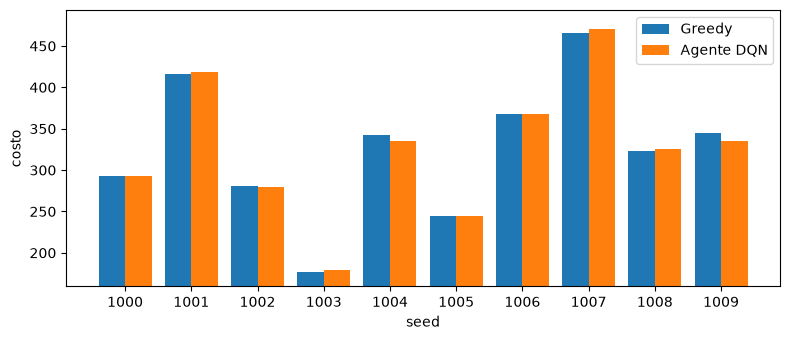

In [6]:
SEEDS = list(range(1000,1010))
filas = []
for s in SEEDS:
    if not pedir("GET", f"/terreno/{s}")["resoluble"]:
        continue
    r = pedir("POST", "/resolver", {"seed": s})
    filas.append((s, r["n_viajes"], r["greedy"]["costo"], r["agente"]["costo"], r["mejora_vs_greedy_pct"]))

print(f"{'seed':>4} {'viajes':>6} {'greedy':>7} {'agente':>7} {'mejora %':>9}")
for s, n, cg, ca, m in filas:
    print(f"{s:>4} {n:>6} {cg:>7.0f} {ca:>7.0f} {m:>9.2f}")
costo_g = np.mean([f[2] for f in filas]); costo_a = np.mean([f[3] for f in filas])
print(f"\nPromedio: greedy {costo_g:.2f} | agente {costo_a:.2f} | mejora {100 * (costo_g - costo_a) / costo_g:.2f}%")

fig, eje = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(filas))
eje.bar(x - 0.2, [f[2] for f in filas], 0.4, label="Greedy")
eje.bar(x + 0.2, [f[3] for f in filas], 0.4, label="Agente DQN")
eje.set_xticks(x, [f[0] for f in filas]); eje.set_xlabel("seed"); eje.set_ylabel("costo")
eje.set_ylim(min(min(f[2], f[3]) for f in filas) * 0.9, None)
eje.legend(); plt.tight_layout(); plt.show()